# C2 · Reservas, IBNR e impacto en resultados (complementario, autónomo)

**Tiempo estimado:** 45–60 min · **Requisitos:** sesiones 2 y 4

> 🔑 **Versión con soluciones.**

**Pregunta de FP&A:** *el coste de siniestros de mi cuenta de resultados, ¿es solo lo declarado? ¿Qué pasa con los siniestros que ya han ocurrido pero todavía no conocemos?*

| Bloque | Contenido |
|---|---|
| 1 | Por qué importa: el IBNR en nuestra propia cartera |
| 2 | El triángulo de desarrollo y el método chain-ladder (con pandas) |
| 3 | Incertidumbre de la reserva: Mack y bootstrap (paquete `chainladder`) |
| 4 | Back-test con datos reales: ¿cuánto acertó la reserva? |

> ⚠️ **En Colab**, la primera ejecución de la celda de preparación instala `chainladder` y **reinicia el entorno**. Cuando reconecte, vuelve a ejecutarla y sigue.

In [1]:
# @title ⚙️ Ejecuta esta celda primero (prepara el entorno) { display-mode: "form" }
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/SSerraPe/curso-python-finanzas.git"
COPIA_DRIVE = Path("/content/drive/MyDrive/curso-python-finanzas")  # la crea el notebook 00
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
    except Exception as e:
        print("⚠️ No se ha podido conectar Google Drive:", e)
    if COPIA_DRIVE.is_dir():
        os.chdir(COPIA_DRIVE)
    else:
        print("⚠️ No encuentro tu copia del curso en Mi unidad › curso-python-finanzas (ver notebook 00).")
        print("   Uso una copia TEMPORAL: lo que generes se pierde al cerrar Colab.")
        if not Path("/content/curso-python-finanzas").exists():
            subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, "/content/curso-python-finanzas"], check=True)
        os.chdir("/content/curso-python-finanzas")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
    try:
        import chainladder  # noqa: F401
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "chainladder==0.10.1"], check=True)
        print("🔄 Se ha instalado chainladder y Colab se reiniciará. Cuando reconecte, VUELVE A EJECUTAR ESTA CELDA.")
        os.kill(os.getpid(), 9)
else:
    # En tu ordenador: nos situamos en la carpeta raíz del curso (la que tiene data/ y src/)
    while not (Path("data").is_dir() and Path("src").is_dir()) and Path.cwd() != Path.cwd().parent:
        os.chdir("..")

sys.path.insert(0, str(Path("src").resolve()))
print("✅ Entorno listo. Carpeta de trabajo:", Path.cwd())

✅ Entorno listo. Carpeta de trabajo: /content/curso-python-finanzas


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import chainladder as cl

warnings.filterwarnings("ignore")   # chainladder emite avisos numéricos internos que no afectan al resultado

from curso_seguros.datos import DATA, cargar_siniestros_referencia
from curso_seguros.comprobar import comprobar

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("chainladder", cl.__version__, "| pandas", pd.__version__)

chainladder 0.10.1 | pandas 3.0.6


---
# Bloque 1 · Por qué importa: el IBNR

En la sesión 3 calculamos el coste de siniestros con lo **declarado** en cada bordereau. Pero un siniestro ocurrido el 28 de diciembre puede declararse en enero, o en marzo. Además, los siniestros ya declarados siguen **evolucionando**: se reabren, crece la estimación del daño corporal…

- **IBNR** (*Incurred But Not Reported*): siniestros ocurridos y aún no declarados.
- La **provisión técnica** de siniestros = pagos futuros esperados de todo lo ya ocurrido. Su variación **va directa a la cuenta de resultados**: si la reserva se queda corta, el beneficio de hoy es un "préstamo" del futuro.

Veámoslo en nuestra cartera de 2025:

In [3]:
sin = cargar_siniestros_referencia()
tardios = sin[sin["fecha_declaracion"] >= "2026-01-01"]
print(f"Siniestros ocurridos en 2025 y declarados en 2026: {len(tardios)} ({len(tardios) / len(sin):.1%})")
print(f"Coste: {tardios['importe'].sum() / 1e6:,.2f} M€ ({tardios['importe'].sum() / sin['importe'].sum():.1%} del coste 2025)")
print(f"Retraso medio de declaración: {(tardios['fecha_declaracion'] - tardios['fecha_ocurrencia']).dt.days.mean():.0f} días")

Siniestros ocurridos en 2025 y declarados en 2026: 957 (3.6%)
Coste: 1.72 M€ (2.9% del coste 2025)
Retraso medio de declaración: 169 días


Si cerráramos 2025 solo con lo declarado a 31/12, el coste estaría **infravalorado** en esa cantidad y el margen, **sobrevalorado**. En la vida real esto es más grave aún en ramos de "cola larga" (RC general, accidentes de trabajo), donde los siniestros tardan años en cerrarse.

---
# Bloque 2 · El triángulo de desarrollo y el chain-ladder

### El triángulo
Filas = **año de ocurrencia**; columnas = **meses de desarrollo** (cuánto tiempo ha pasado desde el inicio del año de ocurrencia); valores = **pagos acumulados**. El triángulo inferior (el futuro) está vacío: es lo que hay que estimar.

Usamos el triángulo clásico **RAA** (Reinsurance Association of America, 1981–1990), un ejemplo estándar de la literatura actuarial.

In [4]:
raa = pd.read_csv(DATA / "triangulos" / "raa.csv")
triangulo = raa.pivot(index="anio_ocurrencia", columns="desarrollo_meses", values="pagos_acumulados")
triangulo

desarrollo_meses,12,24,36,48,60,72,84,96,108,120
anio_ocurrencia,,,,,,,,,,
1981,"5,012.000","8,269.000","10,907.000","11,805.000","13,539.000","16,181.000","18,009.000","18,608.000","18,662.000","18,834.000"
1982,106.000,"4,285.000","5,396.000","10,666.000","13,782.000","15,599.000","15,496.000","16,169.000","16,704.000",NaN
1983,"3,410.000","8,992.000","13,873.000","16,141.000","18,735.000","22,214.000","22,863.000","23,466.000",NaN,NaN
1984,"5,655.000","11,555.000","15,766.000","21,266.000","23,425.000","26,083.000","27,067.000",NaN,NaN,NaN
1985,"1,092.000","9,565.000","15,836.000","22,169.000","25,955.000","26,180.000",NaN,NaN,NaN,NaN
1986,"1,513.000","6,445.000","11,702.000","12,935.000","15,852.000",NaN,NaN,NaN,NaN,NaN
1987,557.000,"4,020.000","10,946.000","12,314.000",NaN,NaN,NaN,NaN,NaN,NaN
1988,"1,351.000","6,947.000","13,112.000",NaN,NaN,NaN,NaN,NaN,NaN,NaN
1989,"3,133.000","5,395.000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Factores de desarrollo (*age-to-age*)
¿Cuánto crecen, de media, los pagos acumulados al pasar de 12 a 24 meses? Del 24 al 36…

El factor se calcula **ponderado por volumen**: Σ columna siguiente / Σ columna actual, usando solo los años que tienen ambos valores. ¡Otra vez el **cociente de sumas** (sesión 2)!

$$f_{j} = \frac{\sum_i C_{i,j+1}}{\sum_i C_{i,j}}$$

### ✏️ Ejercicio 2.1
Calcula `factores`: una Series con los 9 factores de desarrollo (12→24, 24→36, …, 108→120).

Pista: para cada par de columnas consecutivas `a`, `b`, quédate con las filas en que `b` no es nulo: `m = triangulo[b].notna()` y después `triangulo.loc[m, b].sum() / triangulo.loc[m, a].sum()`.

In [5]:
columnas = triangulo.columns.tolist()
factores = {}
for a, b in zip(columnas[:-1], columnas[1:]):
    m = triangulo[b].notna()
    factores[f"{a}-{b}"] = triangulo.loc[m, b].sum() / triangulo.loc[m, a].sum()
factores = pd.Series(factores)
factores

12-24     2.999
24-36     1.624
36-48     1.271
48-60     1.172
60-72     1.113
72-84     1.042
84-96     1.033
96-108    1.017
108-120   1.009
dtype: float64

In [6]:
_ref = cl.Development().fit(cl.load_sample("raa")).ldf_.to_frame().iloc[0].to_numpy()
comprobar(lambda: factores.to_numpy(), _ref, "Usa solo las filas donde la columna siguiente tiene dato", rtol=1e-6)

✅ ¡Correcto!


In [7]:
# 🛟 Red de seguridad
if not isinstance(factores, pd.Series) or len(factores) != len(columnas) - 1:
    factores = pd.Series({f"{a}-{b}": triangulo.loc[triangulo[b].notna(), b].sum() / triangulo.loc[triangulo[b].notna(), a].sum()
                          for a, b in zip(columnas[:-1], columnas[1:])})
    print("🛟 Usando la solución de referencia")

### Del factor a la última y al IBNR
- **CDF** (factor acumulado hasta el final) = producto de los factores pendientes.
- **Última estimada** = último valor conocido × CDF.
- **Reserva (IBNR en sentido amplio)** = última − pagado hasta hoy.

In [8]:
cdf = factores[::-1].cumprod()[::-1]          # producto acumulado desde el final
cdf = pd.concat([cdf, pd.Series({"120-ult": 1.0})])
ultimo_conocido = triangulo.ffill(axis=1).iloc[:, -1]
edad_actual = triangulo.notna().sum(axis=1)                  # nº de diagonales conocidas
cdf_por_anio = edad_actual.map(lambda k: cdf.iloc[k - 1])

resultado = pd.DataFrame({"pagado": ultimo_conocido, "CDF": cdf_por_anio,
                          "ultima": ultimo_conocido * cdf_por_anio})
resultado["reserva"] = resultado["ultima"] - resultado["pagado"]
resultado.loc["Total"] = resultado.sum(numeric_only=True)
resultado.loc["Total", "CDF"] = np.nan
resultado

,pagado,CDF,ultima,reserva
anio_ocurrencia,,,,
1981,"18,834.000",1.000,"18,834.000",0.000
1982,"16,704.000",1.009,"16,857.954",153.954
1983,"23,466.000",1.026,"24,083.371",617.371
1984,"27,067.000",1.060,"28,703.142","1,636.142"
1985,"26,180.000",1.105,"28,926.736","2,746.736"
1986,"15,852.000",1.230,"19,501.103","3,649.103"
1987,"12,314.000",1.441,"17,749.303","5,435.303"
1988,"13,112.000",1.832,"24,019.193","10,907.193"
1989,"5,395.000",2.974,"16,044.984","10,649.984"


Fíjate en 1990: solo conocemos 12 meses y su CDF es ~9. **Un pequeño error en el primer pago se multiplica por 9.** Los años más recientes concentran casi toda la incertidumbre.

---
# Bloque 3 · Incertidumbre de la reserva

La reserva es una **estimación**, no un número exacto. El paquete `chainladder` (mantenido con apoyo de la *Casualty Actuarial Society*) hace todo lo anterior en una línea y añade medidas de incertidumbre.

In [9]:
tri = cl.Triangle(raa, origin="anio_ocurrencia", development="desarrollo_meses",
                  columns="pagos_acumulados", cumulative=True)
modelo = cl.Chainladder().fit(tri)
print(f"Reserva chain-ladder (paquete): {modelo.ibnr_.sum():,.0f}  |  la nuestra: {resultado.loc['Total', 'reserva']:,.0f}")

Reserva chain-ladder (paquete): 52,135  |  la nuestra: 52,135


### Método de Mack: error estándar de la reserva

In [10]:
mack = cl.MackChainladder().fit(tri)
resumen_mack = mack.summary_.to_frame()
resumen_mack

,Latest,IBNR,Ultimate,Mack Std Err
1981-01-01,"18,834.000",NaN,"18,834.000",NaN
1982-01-01,"16,704.000",153.954,"16,857.954",142.932
1983-01-01,"23,466.000",617.371,"24,083.371",592.148
1984-01-01,"27,067.000","1,636.142","28,703.142",712.854
1985-01-01,"26,180.000","2,746.736","28,926.736","1,452.090"
1986-01-01,"15,852.000","3,649.103","19,501.103","1,994.988"
1987-01-01,"12,314.000","5,435.303","17,749.303","2,203.838"
1988-01-01,"13,112.000","10,907.193","24,019.193","5,354.341"
1989-01-01,"5,395.000","10,649.984","16,044.984","6,331.543"
1990-01-01,"2,063.000","16,339.443","18,402.443","24,565.776"


In [11]:
total_ibnr = mack.ibnr_.sum()
total_se = mack.total_mack_std_err_.to_numpy().ravel()[0]
print(f"Reserva: {total_ibnr:,.0f} ± {total_se:,.0f} (error estándar = {total_se / total_ibnr:.0%} de la reserva)")

Reserva: 52,135 ± 26,881 (error estándar = 52% de la reserva)


### Bootstrap ODP: la distribución completa
Igual que en la sesión 4: se generan miles de triángulos "posibles" compatibles con los datos y se recalcula la reserva en cada uno.

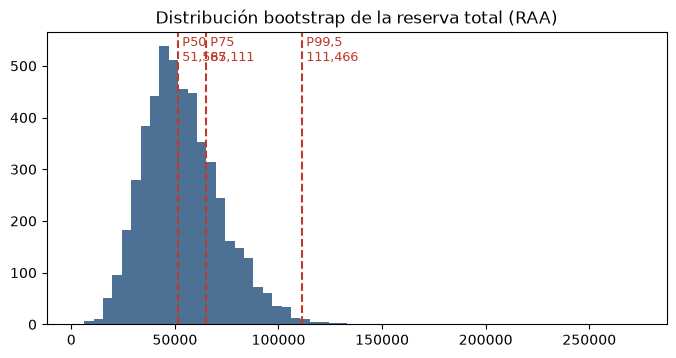

Media 53,826 | P99,5 = 2.1 veces la media


In [12]:
sims = cl.BootstrapODPSample(n_sims=5000, random_state=42).fit_transform(tri)
reservas_sim = cl.Chainladder().fit(sims).ibnr_.sum("origin").to_frame().to_numpy().ravel()

p50, p75, p995 = np.percentile(reservas_sim, [50, 75, 99.5])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(reservas_sim, bins=60, color="#1f4e79", alpha=0.8)
for v, et in [(p50, "P50"), (p75, "P75"), (p995, "P99,5")]:
    ax.axvline(v, color="#c0392b", ls="--")
    ax.text(v, ax.get_ylim()[1] * 0.9, f" {et}\n {v:,.0f}", color="#c0392b", fontsize=9)
ax.set_title("Distribución bootstrap de la reserva total (RAA)")
plt.show()
print(f"Media {reservas_sim.mean():,.0f} | P99,5 = {p995 / reservas_sim.mean():.1f} veces la media")

**Para finanzas:** el **P99,5** es el "1 en 200 años" que usa **Solvencia II** para calcular el capital. Aquí es **más del doble** de la reserva central. Por eso las desviaciones de reservas (*reserve development*) son uno de los grandes motores de sorpresas en la cuenta de resultados de una aseguradora.

---
# Bloque 4 · Back-test con datos reales: ¿cuánto acertó la reserva?

La **CAS Loss Reserving Database** contiene triángulos reales de aseguradoras estadounidenses (Schedule P, autos particulares, ocurrencias 1998–2007) **incluyendo el triángulo inferior**: sabemos qué pasó después. Así podemos comprobar cuánto acierta el chain-ladder.

In [13]:
cas = pd.read_csv(DATA / "triangulos" / "cas_ppauto_1998_2007.csv")
print(cas["compania"].nunique(), "compañías")
cas.head()

136 compañías


,compania,anio_ocurrencia,desarrollo_meses,pagos_acumulados,incurrido,prima_devengada_neta
0,Aegis Grp,1999,12,39.000,270.000,388.000
1,Aegis Grp,1999,24,286.000,298.000,388.000
2,Aegis Grp,1999,36,296.000,296.000,388.000
3,Aegis Grp,1999,48,311.000,326.000,388.000
4,Aegis Grp,1999,60,311.000,311.000,388.000


In [14]:
COMPANIA = "State Farm Mut Grp"
c = cas[cas["compania"] == COMPANIA].copy()
completo = c.pivot(index="anio_ocurrencia", columns="desarrollo_meses", values="pagos_acumulados")
# Lo que se sabía a 31/12/2007: año de ocurrencia + años de desarrollo - 1 <= 2007
conocido = completo.copy()
for anio in conocido.index:
    for meses in conocido.columns:
        if anio + meses // 12 - 1 > 2007:
            conocido.loc[anio, meses] = np.nan
(conocido / 1e3).round(0)       # millones de dólares (los datos originales vienen en miles)

desarrollo_meses,12,24,36,48,60,72,84,96,108,120
anio_ocurrencia,,,,,,,,,,
1998,"4,303.000","7,134.000","8,478.000","9,255.000","9,655.000","9,835.000","9,925.000","9,973.000","9,996.000","10,013.000"
1999,"4,436.000","7,405.000","8,793.000","9,534.000","9,910.000","10,106.000","10,208.000","10,254.000","10,283.000",NaN
2000,"4,796.000","8,102.000","9,466.000","10,208.000","10,633.000","10,830.000","10,929.000","10,981.000",NaN,NaN
2001,"5,329.000","8,822.000","10,243.000","11,064.000","11,504.000","11,721.000","11,838.000",NaN,NaN,NaN
2002,"5,860.000","9,417.000","10,927.000","11,777.000","12,246.000","12,491.000",NaN,NaN,NaN,NaN
2003,"5,504.000","8,823.000","10,228.000","11,083.000","11,561.000",NaN,NaN,NaN,NaN,NaN
2004,"5,234.000","8,449.000","9,835.000","10,710.000",NaN,NaN,NaN,NaN,NaN,NaN
2005,"5,168.000","8,339.000","9,772.000",NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006,"5,174.000","8,387.000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
def chain_ladder(tri):
    """Chain-ladder ponderado por volumen. Devuelve (última estimada, pagado) por año."""
    cols = tri.columns.tolist()
    f = [tri.loc[tri[b].notna(), b].sum() / tri.loc[tri[b].notna(), a].sum() for a, b in zip(cols[:-1], cols[1:])]
    cdf = np.append(np.cumprod(f[::-1])[::-1], 1.0)
    pagado = tri.ffill(axis=1).iloc[:, -1]
    edad = tri.notna().sum(axis=1)
    return pagado * edad.map(lambda k: cdf[k - 1]), pagado

ultima_est, pagado = chain_ladder(conocido)
backtest = pd.DataFrame({"pagado_2007": pagado, "ultima_estimada": ultima_est,
                         "ultima_real (a 120 meses)": completo.iloc[:, -1]})
backtest["reserva_estimada"] = backtest["ultima_estimada"] - backtest["pagado_2007"]
backtest["reserva_real"] = backtest["ultima_real (a 120 meses)"] - backtest["pagado_2007"]
backtest["error_%"] = backtest["reserva_estimada"] / backtest["reserva_real"] - 1
(backtest / [1e3, 1e3, 1e3, 1e3, 1e3, 1]).round(2)   # importes en millones de dólares

,pagado_2007,ultima_estimada,ultima_real (a 120 meses),reserva_estimada,reserva_real,error_%
anio_ocurrencia,,,,,,
1998,"10,012.520","10,012.520","10,012.520",0.000,0.000,NaN
1999,"10,283.290","10,300.530","10,305.660",17.240,22.380,-0.230
2000,"10,981.120","11,027.860","11,033.560",46.740,52.440,-0.110
2001,"11,837.900","11,944.520","11,953.730",106.620,115.830,-0.080
2002,"12,490.510","12,724.110","12,738.350",233.600,247.840,-0.060
2003,"11,561.290","12,003.350","12,057.900",442.060,496.610,-0.110
2004,"10,710.160","11,576.910","11,630.040",866.750,919.880,-0.060
2005,"9,772.150","11,442.980","11,511.380","1,670.830","1,739.230",-0.040
2006,"8,386.580","11,482.100","11,554.420","3,095.520","3,167.840",-0.020


> Matiz: para los años más recientes, "120 meses" todavía no es el cierre definitivo, pero sí una muy buena aproximación.

### ✏️ Ejercicio 4.1
Calcula `error_total`: el error relativo de la reserva **total** (suma de todos los años) de esta compañía = reserva estimada total / reserva real total − 1. ¿El método se quedó corto o se pasó?

In [16]:
error_total = backtest["reserva_estimada"].sum() / backtest["reserva_real"].sum() - 1
print(f"Error de la reserva total: {error_total:+.1%}")

Error de la reserva total: -2.5%


In [17]:
comprobar(lambda: error_total, backtest["reserva_estimada"].sum() / backtest["reserva_real"].sum() - 1,
          "Suma primero (cociente de sumas) y después divide")

✅ ¡Correcto!


⭐ **Opcional:** cambia `COMPANIA` por otra (por ejemplo `"United Services Automobile Asn Grp"` o una pequeña) y repite. ¿En qué compañías acierta peor el chain-ladder? (Pista: en las pequeñas, por la regla ±2/√N de la sesión 4.)

In [18]:
cas.groupby("compania")["prima_devengada_neta"].sum().sort_values(ascending=False).head(15)

compania
State Farm Mut Grp                   1,600,230,750.000
United Services Automobile Asn Grp     271,409,840.000
FL Farm Bureau Grp                      45,303,950.000
New Jersey Manufacturers Grp            43,498,810.000
Kentucky Farm Bureau Mut Ins Grp        23,302,750.000
Federal Ins Co Grp                      20,714,300.000
Tenn Farmers Mut                        20,514,750.000
NC Farm Bureau Ins Grp                  18,064,420.000
IDS Property Cas Ins Co                 15,621,780.000
Dorinco Rein Co                          8,719,810.000
Farm Bureau Of MI Grp                    8,107,130.000
Farmers Automobile Grp                   6,474,020.000
Employers Mut Co Of Des Moines           6,315,920.000
Grinnell Mut Grp                         5,729,780.000
Oklahoma Farm Grp                        5,318,160.000
Name: prima_devengada_neta, dtype: float64

---
## Resumen
- El coste de siniestros del periodo = pagos + **variación de reservas** (incluido el IBNR). Una reserva corta infla el resultado de hoy.
- Chain-ladder: factores ponderados por volumen (cociente de sumas) → CDF → última → reserva.
- La reserva tiene **incertidumbre** importante (Mack, bootstrap), sobre todo en los años recientes.
- El **P99,5** de la reserva enlaza con el capital de Solvencia II.
- Con datos reales se puede hacer **back-testing**: comprobar a posteriori cuánto acertó el método.